# TXDELAY3 plane-wave delays with tilts in both directions

`txdelay3(param, tiltx, tilty)` builds the propagation unit vector by rotating $[0, 0, 1]$ by `tiltx` about the x-axis and then by `tilty` about the y-axis:

$$\hat k = (\sin t_y\cos t_x,\ -\sin t_x,\ \cos t_y\cos t_x)$$

Each element's delay is its distance along $\hat k$ divided by $c$, $\tau_e = \hat k\cdot(x_e, y_e, z_e)/c$, shifted so the first element fires at 0.

The earlier formula, $(x_e\sin t_y - y_e\sin t_x)/c$, lacked the $\cos t_x$ factor and ignored $z_e$.
Below, each bar is one element of the array, and its height is that element's transmit delay.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymust
from pymust.utils import Param

SOUND_SPEED_M_PER_S = 1540
PITCH_M = 300e-6
ELEMENTS_PER_SIDE = 12
M_TO_MM = 1e3
S_TO_US = 1e6

centers_m = (np.arange(ELEMENTS_PER_SIDE) - (ELEMENTS_PER_SIDE - 1) / 2) * PITCH_M
element_x, element_y = (grid.ravel() for grid in np.meshgrid(centers_m, centers_m))
planar_array = Param(fc=3e6, bandwidth=70, width=270e-6, height=270e-6,
                     elements=np.stack([element_x, element_y]))   # (x, y) rows: z = 0

In [2]:
def plot_delays_3d(ax, param, delays_s, title, scale=S_TO_US, unit="µs"):
    element_x, element_y, _ = param.get_element_coordinates()
    heights = np.ravel(delays_s) * scale
    bar_size_mm = 0.8 * PITCH_M * M_TO_MM
    colors = plt.cm.viridis((heights - heights.min()) / (np.ptp(heights) or 1))
    ax.bar3d(element_x * M_TO_MM - bar_size_mm / 2, element_y * M_TO_MM - bar_size_mm / 2,
             np.minimum(heights, 0), bar_size_mm, bar_size_mm, np.abs(heights), color=colors, shade=True)
    ax.set(title=title, xlabel="x (mm)", ylabel="y (mm)", zlabel=f"delay ({unit})")

## Delays for several tilt combinations
- **Top row:** only one tilt at a time, so the delays are a linear ramp along x or y. These match the earlier formula exactly.
- **Bottom row:** both tilts are non-zero, so the ramp runs diagonally across the array.

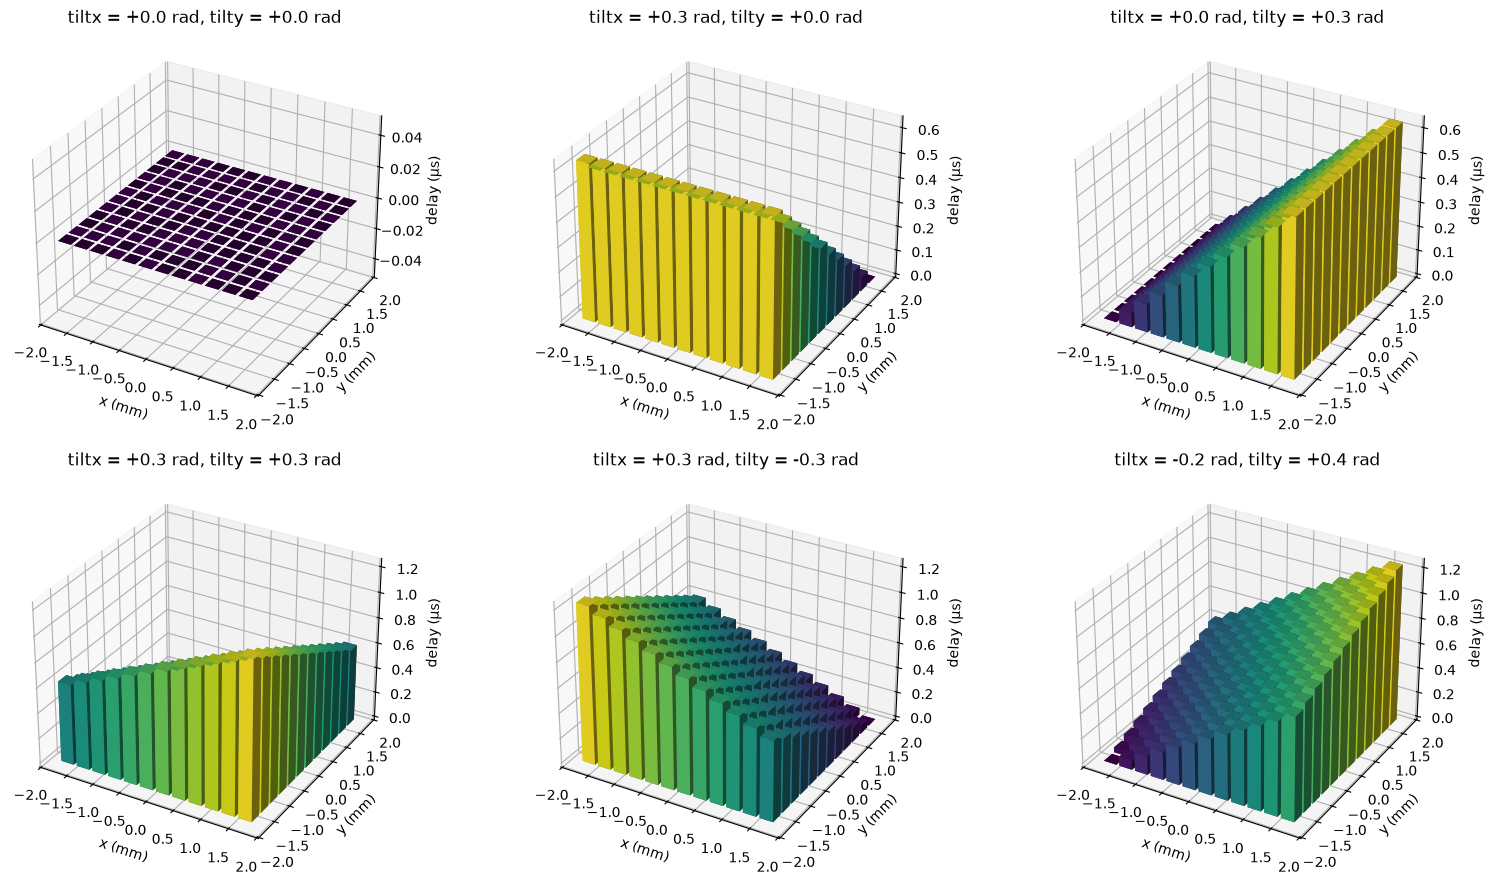

In [3]:
tilt_pairs_rad = [(0.0, 0.0), (0.3, 0.0), (0.0, 0.3), (0.3, 0.3), (0.3, -0.3), (-0.2, 0.4)]

fig = plt.figure(figsize=(16, 9))
for index, (tilt_x_rad, tilt_y_rad) in enumerate(tilt_pairs_rad, start=1):
    delays = pymust.txdelay3(planar_array.copy(), tilt_x_rad, tilt_y_rad)
    ax = fig.add_subplot(2, 3, index, projection="3d")
    plot_delays_3d(ax, planar_array, delays, f"tiltx = {tilt_x_rad:+.1f} rad, tilty = {tilt_y_rad:+.1f} rad")
fig.tight_layout()

## What changed: new minus earlier delays, both tilts non-zero
The earlier x-term $x_e\sin t_y$ becomes $x_e\sin t_y\cos t_x$ in the new formula. The difference therefore grows linearly with $x_e$ and is exactly zero whenever either tilt is 0.

max |new − earlier| = 28.28 ns


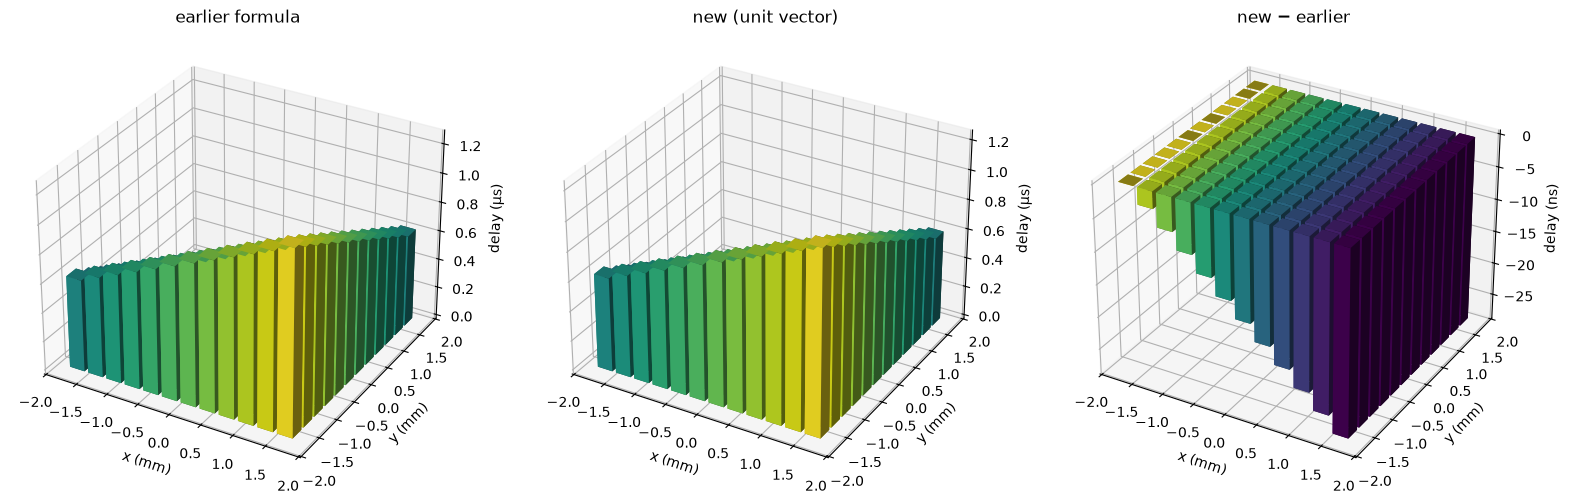

In [4]:
tilt_x_rad, tilt_y_rad = 0.3, 0.3
new_delays = pymust.txdelay3(planar_array.copy(), tilt_x_rad, tilt_y_rad).ravel()
earlier_delays = (element_x * np.sin(tilt_y_rad) - element_y * np.sin(tilt_x_rad)) / SOUND_SPEED_M_PER_S
earlier_delays -= earlier_delays.min()

fig = plt.figure(figsize=(16, 5))
for index, (delays, title) in enumerate([(earlier_delays, "earlier formula"), (new_delays, "new (unit vector)")], start=1):
    plot_delays_3d(fig.add_subplot(1, 3, index, projection="3d"), planar_array, delays, title)
plot_delays_3d(fig.add_subplot(1, 3, 3, projection="3d"), planar_array, new_delays - earlier_delays,
               "new − earlier", scale=1e9, unit="ns")
fig.tight_layout()
print(f"max |new − earlier| = {np.abs(new_delays - earlier_delays).max() * 1e9:.2f} ns")

## Curved array: the element heights $z_e$ now contribute to the delays
- **Array:** the same 12×12 grid, placed on a spherical cap of radius 10 mm and given as 3-row `elements` (x, y, z).
- **Normal incidence (no tilt):** the delays now follow the cap shape. Previously every element got the same delay, because $z_e$ was ignored.

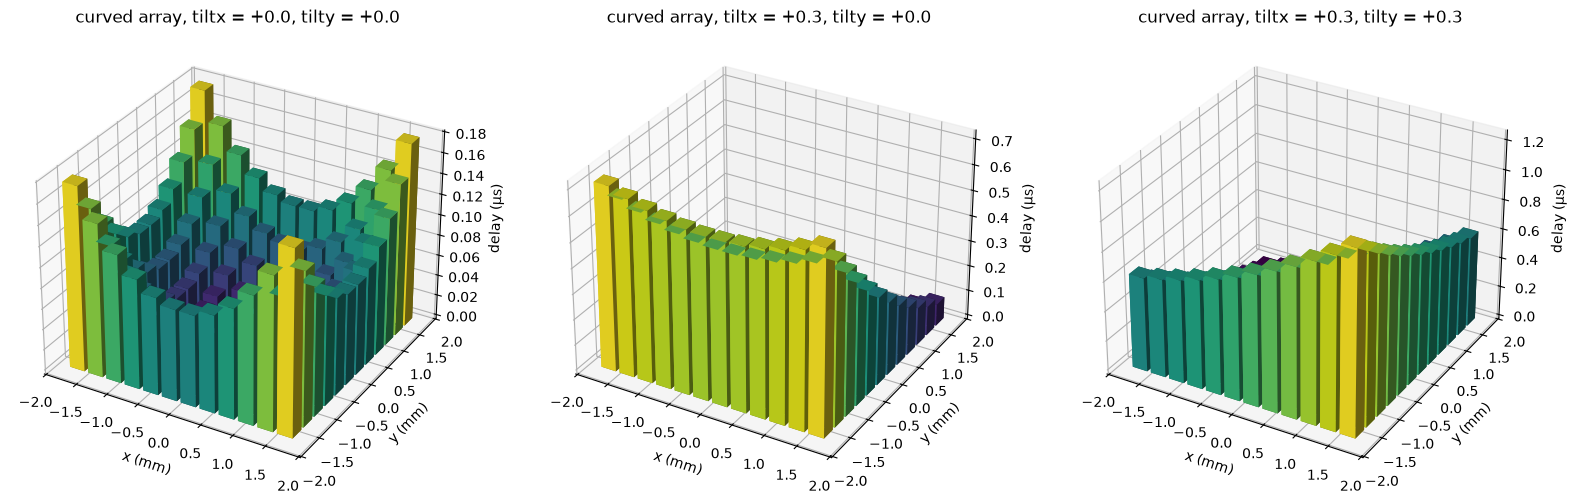

In [5]:
CAP_RADIUS_M = 10e-3
element_z = CAP_RADIUS_M - np.sqrt(CAP_RADIUS_M**2 - element_x**2 - element_y**2)
curved_array = Param(fc=3e6, bandwidth=70, width=270e-6, height=270e-6,
                     elements=np.stack([element_x, element_y, element_z]))

fig = plt.figure(figsize=(16, 5))
for index, (tilt_x_rad, tilt_y_rad) in enumerate([(0.0, 0.0), (0.3, 0.0), (0.3, 0.3)], start=1):
    delays = pymust.txdelay3(curved_array.copy(), tilt_x_rad, tilt_y_rad)
    plot_delays_3d(fig.add_subplot(1, 3, index, projection="3d"), curved_array, delays,
                   f"curved array, tiltx = {tilt_x_rad:+.1f}, tilty = {tilt_y_rad:+.1f}")
fig.tight_layout()

## The curved array in 3-D (interactive)
`plot_transducer_array` draws each element as a box: width (x) × height (y) × thickness (z, 0.5 mm by default).
It needs plotly: `pip install pymust[plot]`.

In [6]:
pymust.utils.plot_transducer_array(curved_array)